In [1]:
import warnings
warnings.simplefilter('ignore')

In [2]:
import pandas as pd
import matplotlib.pyplot as plot
import matplotlib.dates as mdates
import seaborn as sns
from plotly.offline import plot as plt
import plotly.graph_objs as go
import plotly.io as pio
import time
from datetime import datetime, timedelta, date
import teradata
import  businessdays as bzd
import plotly.express as px
import ipywidgets as widgets
from IPython.display import display, clear_output 

In [3]:

start = time.time() 
system = "TERADBAWS.sicredi.net"
user = "P_USR_DL_GESTAO_RECURSOS"
passw = "JAW0b71329aadade35365afc6X"
udaExec = teradata.UdaExec (appName="TESTE", version="1.0", logConsole=False)
session = udaExec.connect(method="odbc", system=system,
        username=user, password=passw, Authentication="TDNEGO");


select_feriados = "Select DT from dl_Gestao_recursos.bas_cad_fer where tipo in ('3','2')"
feriados = pd.read_sql(select_feriados, session)
cal = bzd.Calendar(holidays=feriados.DT,weekdays=['Sunday','Saturday'])

data_inicial = cal.offset(datetime.now(),-60  )###DATA PADRÃO D-180
data_inicial = data_inicial.strftime('%Y-%m-%d') ###DATA PADRÃO D-180

data_final = cal.offset(datetime(2025,1,8),0)###DATA PADRÃO D-1
data_final = data_final.strftime('%Y-%m-%d') ###DATA PADRÃO D-1

#data_inicial='2023-01-01'
#data_final='2023-07-25'

In [4]:
Select = f"""
        SELECT VAR.DTPOS, VAR.NOMECARTEIRA, VAR.CODCARTEIRAN2, VAR.CODCARTEIRAN3, DECODE(VAR.GRUPO,'Total', 'TOTAL',DECODE(VAR.CODCARTEIRAN2,'Arbitragem', 'ARBITRAGEM','Moedas','MOEDAS',VAR.CODCARTEIRAN3)) as Estrategia
        , -VAR.var as VaR, -VAR.var21 as VaR21, VAR.Estresse, -VAR.Cvar as CVaR, VAR.ES as ExpectedShorFall, VAR.vlrMaM as MtM
        ,PL.VL_PATRLIQTOT1, -VAR.CVaR/PL.VL_PATRLIQTOT1 AS CVaR_PL, -VAR/PL.VL_PATRLIQTOT1 AS VaR_PL
        ,  VAR.vlrMaM/PL.VL_PATRLIQTOT1 AS MtM_PL
        , -VAR.ES/PL.VL_PATRLIQTOT1 AS ExpectedShortFall_PL
        , -VAR.ESTRESSE/PL.VL_PATRLIQTOT1 AS Estresse_PL
        , case when VAR.vlrMaM is null or VAR.vlrMaM = 0 then null else mtm-var.var/VAR.vlrMaM end as VaR_MtM

        FROM DL_GESTAO_RECURSOS.VAR_ESTRATEGIA_SAS VAR
        left join dl_Gestao_recursos.sac_cl_patrsint pl on pl.dt = VAR.DTPOS AND VAR.NOMECARTEIRA = PL.CLCLI_CD
        WHERE VAR.DTPOS >= '{data_inicial}' and ((VAR.codproduto is null and (case when VAR.CODCARTEIRAN2 = 'Arbitragem' then VAR.CODCARTEIRAN3 ELSE NULL END IS NULL)
        and DECODE(VAR.CODCARTEIRAN2,'Arbitragem', VAR.CODCARTEIRAN2,VAR.CODCARTEIRAN3) is not null) OR (VAR.GRUPO = 'Total'))
        """

df_var = pd.read_sql(Select, session) 
df_var.DtPos = pd.to_datetime(df_var.DtPos, format='%Y-%m-%d')
df_var = df_var.sort_values(by = ['Estrategia', 'NomeCarteira','DtPos'])

In [5]:
dropdown_carteira = widgets.Dropdown(
    options=df_var["NomeCarteira"].unique(),
    description='Nome Carteira:',
    disabled=False,
)

dropdown_valor = widgets.Dropdown(
    options=[col for col in df_var.columns if col != "Categoria"],
    description='Valor Y:',
    disabled=False,
)

# Função para atualizar o gráfico com base na seleção do menu suspenso
def update_plot(carteira, valor_y):
    df_filtro = df_var[df_var["NomeCarteira"] == dropdown_carteira.value]
    df_filtro = df_filtro[df_filtro['Estrategia'] != 'TOTAL']
    df_total = df_filtro[df_filtro['Estrategia'] == 'TOTAL']
    valor = valor_y.replace("_", "/")
    fig = px.bar(df_filtro, x='DtPos', y=valor_y, color='Estrategia', title=f'Histórico de Risco - {carteira} ({valor})')
    #fig = px.line(df_total, x='DtPos', y=valor_y)
    fig.show()
    

final = widgets.interactive_output(update_plot, {'carteira': dropdown_carteira, 'valor_y': dropdown_valor})

# Exibindo o menu suspenso e o gráfico inicial
display(dropdown_carteira, dropdown_valor, final)

Dropdown(description='Nome Carteira:', options=('FI ICATU SOBERA', 'FIRF ALOCACAO', 'FM MACRO ALOC', 'FAPI COM…

Dropdown(description='Valor Y:', options=('DtPos', 'NomeCarteira', 'CodCarteiraN2', 'CodCarteiraN3', 'Estrateg…

Output()

In [6]:

dropdown_carteira = widgets.Dropdown(
    options=df_var["NomeCarteira"].unique(),
    description='Nome Carteira:',
    disabled=False,
)

dropdown_valor = widgets.Dropdown(
    options=[col for col in df_var.columns if col != "Categoria"],
    description='Valor Y:',
    disabled=False,
)
num=1
# Função para atualizar o gráfico com base na seleção do menu suspenso
def update_plot(carteira, valor_y):
    df_filtro = df_var[df_var["NomeCarteira"] == dropdown_carteira.value]
    df_filtro = df_filtro[df_filtro['Estrategia'] != 'TOTAL']
    df_var = df_var.sort_values(by = ['Estrategia', 'NomeCarteira','DtPos'])
    df_filtro = df_filtro.loc[df_filtro.groupby(['NomeCarteira'])['DtPos'].idxmax()]

    df_total = df_filtro[df_filtro['Estrategia'] == 'TOTAL']
    valor = valor_y.replace("_", "/")
    #fig = px.pie(df_filtro,valor_y, names='Estrategia', title=f'Histórico de Risco - {carteira} ({valor})')
    fig = px.pie(df_filtro
               , values=valor_y
               , names='Estrategia'
               , facet_col_wrap=2      
               , facet_col = 'NomeCarteira'
               , height=num*350
               , width=1000             
               )
    #fig = px.line(df_total, x='DtPos', y=valor_y)
    #for annotation in fig.layout.annotations:
    #    #annotation.text = ""  # Removendo o texto do título
    #    annotation.text = annotation.text.replace("NomeCarteira=", "")
    
    fig.show()
    

final = widgets.interactive_output(update_plot, {'carteira': dropdown_carteira, 'valor_y': dropdown_valor})

# Exibindo o menu suspenso e o gráfico inicial
display(dropdown_carteira, dropdown_valor, final)

Dropdown(description='Nome Carteira:', options=('FI ICATU SOBERA', 'FIRF ALOCACAO', 'FM MACRO ALOC', 'FAPI COM…

Dropdown(description='Valor Y:', options=('DtPos', 'NomeCarteira', 'CodCarteiraN2', 'CodCarteiraN3', 'Estrateg…

Output()

In [7]:
df_var_final = df_var.loc[df_var.groupby(['NomeCarteira'])['DtPos'].idxmax()]

In [8]:
import pygwalker as pyg
walker = pyg.walk(df_var_final)

Box(children=(HTML(value='\n<div id="ifr-pyg-00063013ac558cd1pLbm5K3nQXJ1MStr" style="height: auto">\n    <hea…

In [9]:
select = f"""


select RES.DT
, RES.RESULTADO
, VAR.VAR as VAR
, ROUND(SUM(RES.RESULTADO) OVER (PARTITION BY  EXTRACT(YEAR FROM RES.DT) ORDER BY RES.DT ROWS BETWEEN 260 PRECEDING AND CURRENT ROW),2) AS RESULTADO_ACUMULADO
, -ROUND(AVG(VAR.VAR) OVER (PARTITION BY  EXTRACT(YEAR FROM RES.DT) ORDER BY RES.DT ROWS BETWEEN 260 PRECEDING AND CURRENT ROW),2) AS VAR_MEDIO
, ROUND(SUM(RES.RESULTADO) OVER (PARTITION BY  EXTRACT(YEAR FROM RES.DT) ORDER BY RES.DT ROWS BETWEEN 260 PRECEDING AND CURRENT ROW),2)/1500000*100 AS META_FINANCEIRO
, (SUM(RES.RESULTADO) OVER (PARTITION BY  EXTRACT(YEAR FROM RES.DT) ORDER BY RES.DT ROWS BETWEEN 260 PRECEDING AND CURRENT ROW)/-AVG(VAR.VAR) OVER (PARTITION BY  EXTRACT(YEAR FROM RES.DT) ORDER BY RES.DT ROWS BETWEEN 260 PRECEDING AND CURRENT ROW))/5*100 AS META_VAR 
from (select DT, sum(vl_resultado) AS RESULTADO, sum(vl_fatura_bmf) AS RESULTADO_BMF from dl_Gestao_recursos.fu_resultado
where dt between '2025-01-01' and '2025-12-31' and book1 = 'Arbitragem'
group by dt) RES 
LEFT JOIN(SELECT * FROM DL_GESTAO_RECURSOS.VAR_ESTRATEGIA_GLOBAL_SAS
WHERE DTPOS >='2024-01-03' and CODCARTEIRAN3 is null
AND ((GRUPO = 'Carteira N2' AND CODCARTEIRAN2 = 'Arbitragem') OR (GRUPO = 'Carteira N3' AND CODCARTEIRAN2 = 'Arbitragem'))
) VAR ON RES.DT = VAR.DTPOS
where res.dt >= '2024-01-01'


"""

df_fly = pd.read_sql(select, session) 
df_fly.DT = pd.to_datetime(df_fly.DT, format='%Y-%m-%d')
df_fly = df_fly.sort_values(by = ['DT'])


In [10]:
df_fly.to_clipboard(decimal=',')

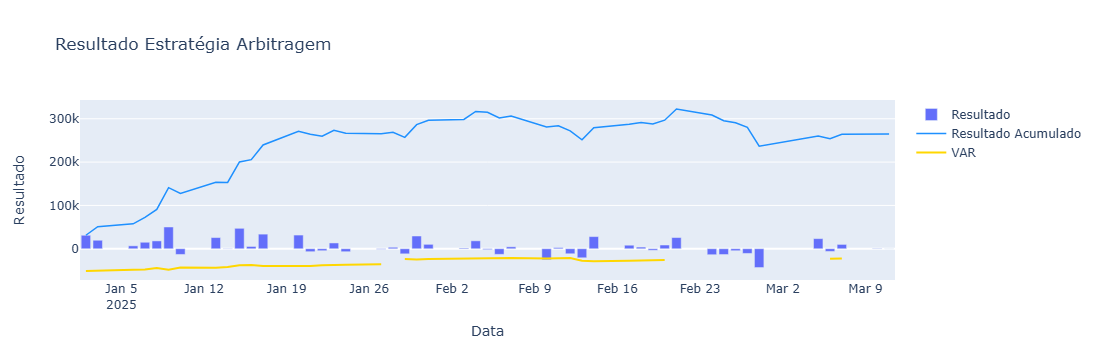

In [11]:
df_fly['RESULTADO'].fillna(value=0, inplace=True)    
RESULTADO = go.Bar(x = df_fly.DT,y = df_fly['RESULTADO'],name = 'Resultado')
RESULTADO_ACUMULADO = go.Scatter(x = df_fly.DT,y = df_fly['RESULTADO_ACUMULADO'],mode = 'lines', name = 'Resultado Acumulado',line = {'color': 'dodgerblue', 'width':1.5})
VAR  = go.Scatter(x = df_fly.DT,y = df_fly['VAR'],mode = 'lines', name = 'VAR', line = {'color': 'gold'})


data2 = [RESULTADO, RESULTADO_ACUMULADO, VAR]
layout = dict(title = 'Resultado Estratégia Arbitragem',
                       xaxis = dict(title = 'Data')
                       ,yaxis = dict(title = 'Resultado')
                       #xaxis_rangeslider_visible=True
                       )
fig2 = go.Figure(data=data2, layout=layout)
fig2.show()

In [27]:
select = f"""
select RES.DT
, RES.RESULTADO
, VAR.VAR
, ROUND(SUM(RES.RESULTADO) OVER (PARTITION BY  EXTRACT(YEAR FROM RES.DT) ORDER BY RES.DT ROWS BETWEEN 260 PRECEDING AND CURRENT ROW),2) AS RESULTADO_ACUMULADO
, -ROUND(AVG(VAR.VAR) OVER (PARTITION BY  EXTRACT(YEAR FROM RES.DT) ORDER BY RES.DT ROWS BETWEEN 260 PRECEDING AND CURRENT ROW),2) AS VAR_MEDIO
, ROUND(SUM(RES.RESULTADO) OVER (PARTITION BY  EXTRACT(YEAR FROM RES.DT) ORDER BY RES.DT ROWS BETWEEN 260 PRECEDING AND CURRENT ROW),2)/1500000*100 AS META_FINANCEIRO
, (SUM(RES.RESULTADO) OVER (PARTITION BY  EXTRACT(YEAR FROM RES.DT) ORDER BY RES.DT ROWS BETWEEN 260 PRECEDING AND CURRENT ROW)/-AVG(VAR.VAR) OVER (PARTITION BY  EXTRACT(YEAR FROM RES.DT) ORDER BY RES.DT ROWS BETWEEN 260 PRECEDING AND CURRENT ROW))/5*100 AS META_VAR 
from (select DT, sum(FINANCEIRO*FL_CONS) - sum(VW.VL_BRUTOPOS_ANT*FL_CONS*idx.valor/3000) AS RESULTADO, sum(FINANCEIRO*FL_CONS) - sum(VW.VL_BRUTOPOS_ANT*FL_CONS*idx.valor/3000)   AS RESULTADO_BMF 
from dl_Gestao_recursos.vw_resultado vw
left join dl_Gestao_recursos.idx_index idx on idx.data = vw.dt_ant1 and idx.codindex = 'CDI'
where dt between '2025-01-01' and '2025-12-31' and CD_ESTRATEGIA_MOV in ('INF_CARRY','INF_TRADE', 'INF_CP') AND CLCLI_CD NOT IN ('IS MASTER DI')
group by dt) RES 
LEFT JOIN(SELECT * FROM DL_GESTAO_RECURSOS.VAR_ESTRATEGIA_GLOBAL_SAS
WHERE DTPOS >='2024-01-03' and CODCARTEIRAN3 is null
AND ((GRUPO = 'Carteira N2' AND CODCARTEIRAN2 = 'Juro Real') OR (GRUPO = 'Carteira N3' AND CODCARTEIRAN2 = 'Juro Real'))
) VAR ON RES.DT = VAR.DTPOS
where res.dt >= '2024-01-01'
"""

df_inf = pd.read_sql(select, session) 
df_inf.DT = pd.to_datetime(df_inf.DT, format='%Y-%m-%d')
df_inf = df_inf.sort_values(by = ['DT'])

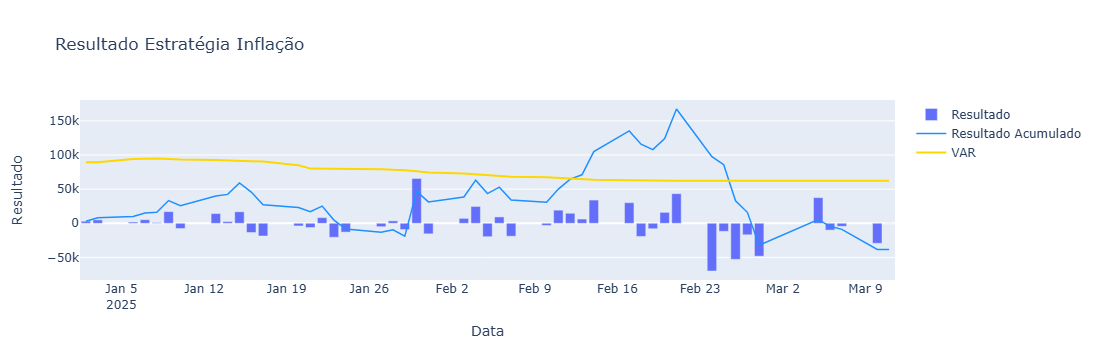

In [28]:
df_inf['RESULTADO'].fillna(value=0, inplace=True)    
RESULTADO = go.Bar(x = df_inf.DT,y = df_inf['RESULTADO'],name = 'Resultado')
RESULTADO_ACUMULADO = go.Scatter(x = df_inf.DT,y = df_inf['RESULTADO_ACUMULADO'],mode = 'lines', name = 'Resultado Acumulado',line = {'color': 'dodgerblue', 'width':1.5})
VAR  = go.Scatter(x = df_inf.DT,y = df_inf['VAR_MEDIO'],mode = 'lines', name = 'VAR', line = {'color': 'gold'})


data2 = [RESULTADO, RESULTADO_ACUMULADO, VAR]
layout = dict(title = 'Resultado Estratégia Inflação',
                       xaxis = dict(title = 'Data')
                       ,yaxis = dict(title = 'Resultado')
                       #xaxis_rangeslider_visible=True
                       )
fig2 = go.Figure(data=data2, layout=layout)
fig2.show()

In [35]:
select = f"""
select RES.DT
, RES.RESULTADO
, VAR.VAR
, ROUND(SUM(RES.RESULTADO) OVER (PARTITION BY  EXTRACT(YEAR FROM RES.DT) ORDER BY RES.DT ROWS BETWEEN 260 PRECEDING AND CURRENT ROW),2) AS RESULTADO_ACUMULADO
, -ROUND(AVG(VAR.VAR) OVER (PARTITION BY  EXTRACT(YEAR FROM RES.DT) ORDER BY RES.DT ROWS BETWEEN 260 PRECEDING AND CURRENT ROW),2) AS VAR_MEDIO
, ROUND(SUM(RES.RESULTADO) OVER (PARTITION BY  EXTRACT(YEAR FROM RES.DT) ORDER BY RES.DT ROWS BETWEEN 260 PRECEDING AND CURRENT ROW),2)/1500000*100 AS META_FINANCEIRO
, (SUM(RES.RESULTADO) OVER (PARTITION BY  EXTRACT(YEAR FROM RES.DT) ORDER BY RES.DT ROWS BETWEEN 260 PRECEDING AND CURRENT ROW)/-AVG(VAR.VAR) OVER (PARTITION BY  EXTRACT(YEAR FROM RES.DT) ORDER BY RES.DT ROWS BETWEEN 260 PRECEDING AND CURRENT ROW))/5*100 AS META_VAR 
from (select DT, sum(FINANCEIRO*FL_CONS) - sum(VW.VL_BRUTOPOS_ANT*FL_CONS*idx.valor/3000) AS RESULTADO, sum(FINANCEIRO*FL_CONS) - sum(VW.VL_BRUTOPOS_ANT*FL_CONS*idx.valor/3000)   AS RESULTADO_BMF 
from dl_Gestao_recursos.vw_resultado vw
left join dl_Gestao_recursos.idx_index idx on idx.data = vw.dt_ant1 and idx.codindex = 'CDI'
where dt between '2025-01-01' and '2025-12-31' and CD_ESTRATEGIA_MOV in ('JUR_CP','JUR_TRADE','JUR_CARRY') AND CLCLI_CD NOT IN ('IS MASTER DI')
group by dt) RES 
LEFT JOIN(SELECT * FROM DL_GESTAO_RECURSOS.VAR_ESTRATEGIA_GLOBAL_SAS
WHERE DTPOS >='2024-01-03' and CODCARTEIRAN3 is null
AND ((GRUPO = 'Carteira N2' AND CODCARTEIRAN2 = 'Juro Real') OR (GRUPO = 'Carteira N3' AND CODCARTEIRAN2 = 'Juro Real'))
) VAR ON RES.DT = VAR.DTPOS
where res.dt >= '2024-01-01'
"""

df_jur = pd.read_sql(select, session) 
df_jur.DT = pd.to_datetime(df_jur.DT, format='%Y-%m-%d')
df_jur = df_jur.sort_values(by = ['DT'])

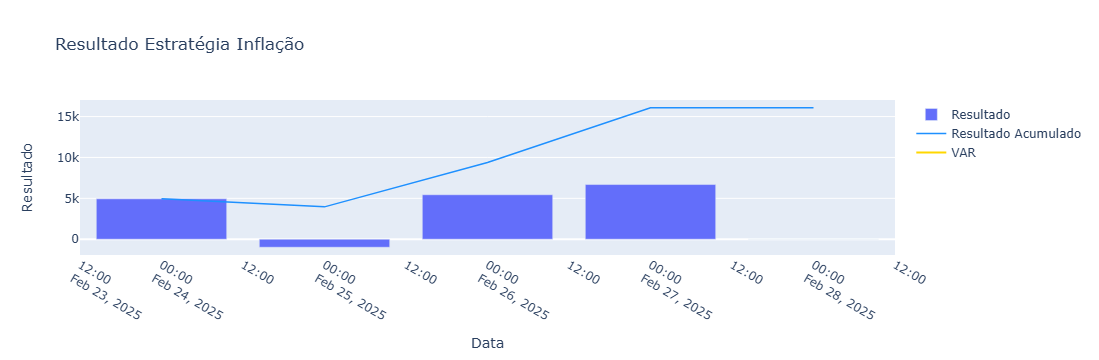

In [36]:
df_jur['RESULTADO'].fillna(value=0, inplace=True)    
RESULTADO = go.Bar(x = df_jur.DT,y = df_jur['RESULTADO'],name = 'Resultado')
RESULTADO_ACUMULADO = go.Scatter(x = df_jur.DT,y = df_jur['RESULTADO_ACUMULADO'],mode = 'lines', name = 'Resultado Acumulado',line = {'color': 'dodgerblue', 'width':1.5})
VAR  = go.Scatter(x = df_jur.DT,y = df_jur['VAR_MEDIO'],mode = 'lines', name = 'VAR', line = {'color': 'gold'})


data2 = [RESULTADO, RESULTADO_ACUMULADO, VAR]
layout = dict(title = 'Resultado Estratégia Inflação',
                       xaxis = dict(title = 'Data')
                       ,yaxis = dict(title = 'Resultado')
                       #xaxis_rangeslider_visible=True
                       )
fig2 = go.Figure(data=data2, layout=layout)
fig2.show()